In [2]:
import pandas as pd

df = pd.read_csv('/content/Loan_Prediction.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
# 1. Display dataset information
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape:
(614, 13)

Column Names:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Pro

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y



Statistical Summary:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000



Missing Values:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Duplicate Rows:
0


In [4]:
print("Loan Status Distribution:")

print(df["Loan_Status"].value_counts())

print("\nLoan Status Percentage:")

print(
    df["Loan_Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Loan Status Distribution:
Loan_Status
Y    422
N    192
Name: count, dtype: int64

Loan Status Percentage:
Loan_Status
Y    68.73
N    31.27
Name: proportion, dtype: float64


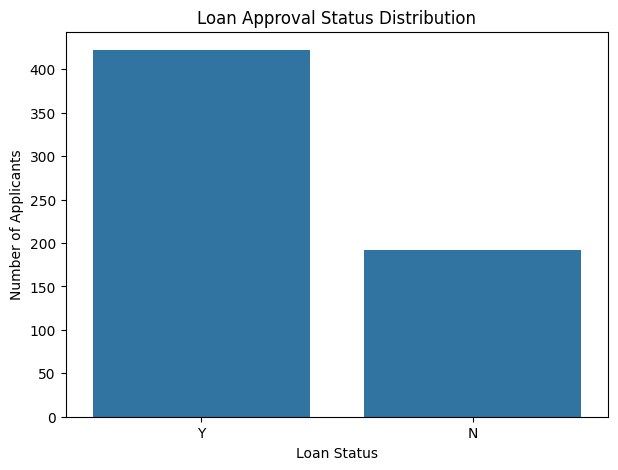

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Loan_Status")

plt.title("Loan Approval Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")

plt.show()

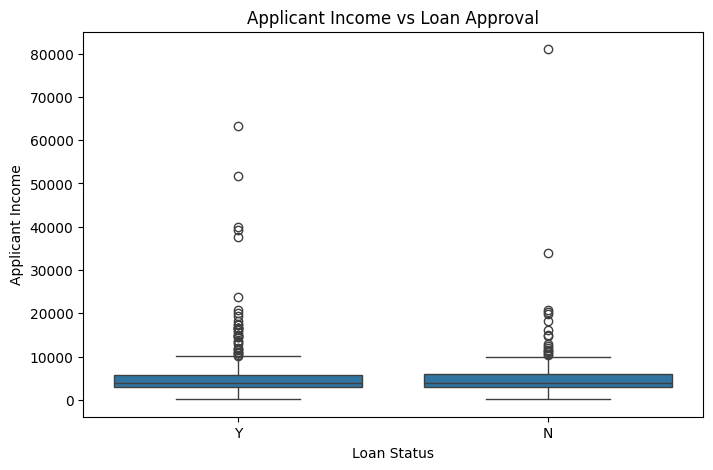

In [6]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Loan_Status",
    y="ApplicantIncome"
)

plt.title("Applicant Income vs Loan Approval")
plt.xlabel("Loan Status")
plt.ylabel("Applicant Income")

plt.show()

In [7]:
# Remove unnecessary Loan_ID column
df = df.drop("Loan_ID", axis=1)

print("Loan_ID column removed successfully!")

print("\nUpdated Dataset Shape:")
print(df.shape)

print("\nRemaining Columns:")
print(df.columns.tolist())

Loan_ID column removed successfully!

Updated Dataset Shape:
(614, 12)

Remaining Columns:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


In [8]:
# Separate input features and target
X = df.drop("Loan_Status", axis=1)

y = df["Loan_Status"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Values:")
print(y.value_counts())

Input Features Shape: (614, 11)
Target Shape: (614,)

Input Features:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']

Target Values:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (491, 11)
Testing Features: (123, 11)

Training Target: (491,)
Testing Target: (123,)


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

Categorical Features:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


In [11]:
# Numerical data preprocessing
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical data preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Define the models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    )
}

# Train each model
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully!")

print("\nAll models trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!

All models trained successfully!


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = []

for name, model in trained_models.items():

    # Predict using unseen test data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, pos_label="Y", zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, pos_label="Y", zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, pos_label="Y", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": round(accuracy * 100, 2),
        "Precision": round(precision * 100, 2),
        "Recall": round(recall * 100, 2),
        "F1-Score": round(f1 * 100, 2)
    })

    print("\n", "=" * 45)
    print("Model:", name)
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))

print("\nAll models evaluated successfully!")


Model: Logistic Regression
              precision    recall  f1-score   support

           N       0.96      0.58      0.72        38
           Y       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123


Model: Decision Tree
              precision    recall  f1-score   support

           N       0.81      0.55      0.66        38
           Y       0.82      0.94      0.88        85

    accuracy                           0.82       123
   macro avg       0.82      0.75      0.77       123
weighted avg       0.82      0.82      0.81       123


Model: Random Forest
              precision    recall  f1-score   support

           N       0.95      0.55      0.70        38
           Y       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
we

In [14]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("Model Performance Comparison:")

display(results_df)

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,86.18,84.00,98.82,90.81
1,Random Forest,85.37,83.17,98.82,90.32
2,Decision Tree,82.11,82.47,94.12,87.91


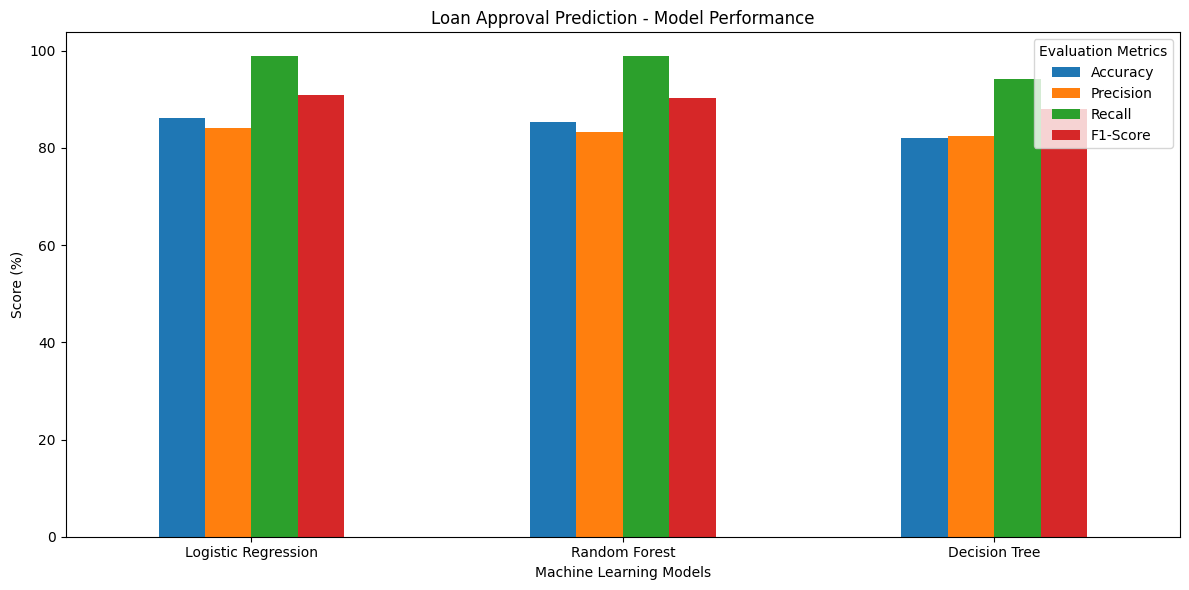

In [15]:
import matplotlib.pyplot as plt

# Prepare model comparison chart
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.plot(
    x="Model",
    y=metrics,
    kind="bar",
    figsize=(12, 6)
)

plt.title("Loan Approval Prediction - Model Performance")
plt.ylabel("Score (%)")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

In [16]:
# Select model with the highest F1-score
best_model_name = results_df.loc[
    results_df["F1-Score"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print(
    "F1-Score:",
    results_df.loc[
        results_df["F1-Score"].idxmax(),
        "F1-Score"
    ],
    "%"
)

Best Model: Logistic Regression
F1-Score: 90.81 %


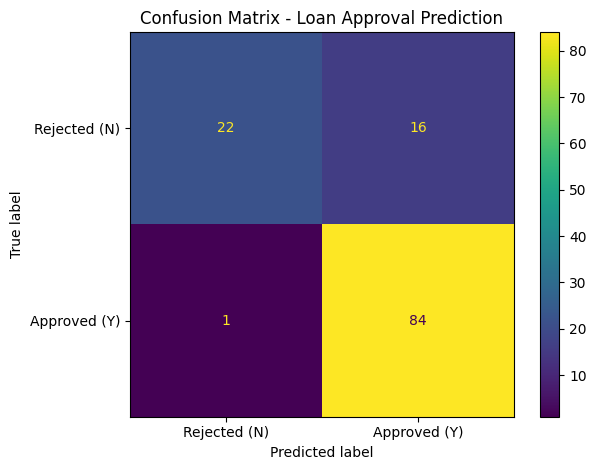

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict using the selected best model
y_pred_best = best_model.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=["N", "Y"]
)

# Visualize the confusion matrix
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected (N)", "Approved (Y)"]
)

display_matrix.plot()

plt.title("Confusion Matrix - Loan Approval Prediction")
plt.tight_layout()
plt.show()

In [18]:
print("PROJECT: LOAN APPROVAL PREDICTION")
print("-" * 40)

print("Best Model:", best_model_name)

print("\nModel Performance:")
display(results_df)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nProject Evaluation Completed!")

PROJECT: LOAN APPROVAL PREDICTION
----------------------------------------
Best Model: Logistic Regression

Model Performance:


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,86.18,84.00,98.82,90.81
1,Random Forest,85.37,83.17,98.82,90.32
2,Decision Tree,82.11,82.47,94.12,87.91



Training Samples: 491
Testing Samples: 123

Project Evaluation Completed!


In [19]:
# Create a sample applicant
new_applicant = pd.DataFrame([{
    "Gender": "Male",
    "Married": "Yes",
    "Dependents": "0",
    "Education": "Graduate",
    "Self_Employed": "No",
    "ApplicantIncome": 5000,
    "CoapplicantIncome": 1500,
    "LoanAmount": 120,
    "Loan_Amount_Term": 360,
    "Credit_History": 1.0,
    "Property_Area": "Urban"
}])

# Predict loan status
prediction = best_model.predict(new_applicant)[0]

print("Loan Approval Prediction")

if prediction == "Y":
    print("Predicted Status: Loan Approved")
else:
    print("Predicted Status: Loan Rejected")

Loan Approval Prediction
Predicted Status: Loan Approved


In [20]:
import joblib

# Save the trained model
joblib.dump(best_model, "loan_approval_model.pkl")

print("Model saved successfully!")
print("Model Name:", best_model_name)
print("File Name: loan_approval_model.pkl")

Model saved successfully!
Model Name: Logistic Regression
File Name: loan_approval_model.pkl


In [21]:
from google.colab import files

files.download("loan_approval_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>